# Praktikum Evaluasi Model Klasifikasi

## 4.1 Menyiapkan Dataset Sintesis

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


## 4.2 Membagi Data dan Melatih Model

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))

Data uji: 150


## 4.3 Menghitung Confusion Matrix

In [3]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


## 4.4 Perhitungan Manual dan Verifikasi

In [4]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,zero_division=0),
      recall_score(y_test,y_pred,zero_division=0), f1_score(y_test,y_pred,zero_division=0))

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


## 4.5 Visualisasi Confusion Matrix

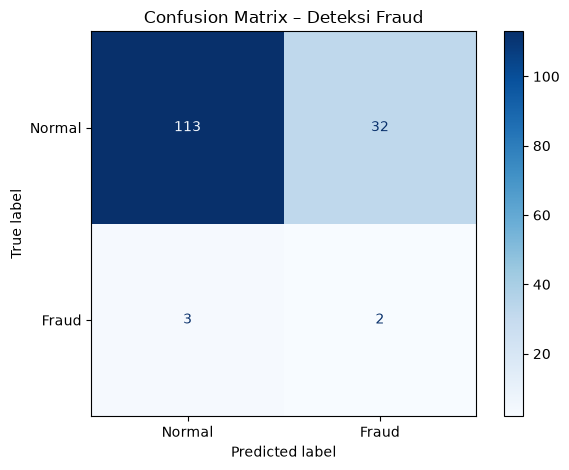

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

## 4.6 Interpretasi dan Studi Kasus

Dalam deteksi fraud, FN berarti transaksi fraud tidak terdeteksi dan berpotensi menimbulkan kerugian; FP 
berarti transaksi normal ditandai fraud dan dapat mengganggu pelanggan. Recall tinggi membantu 
mengurangi fraud yang lolos, tetapi dapat meningkatkan alarm palsu. Pilihan metrik perlu 
mempertimbangkan biaya masing-masing kesalahan.


Analisis:

Model menghasilkan FN = 3 (fraud lolos, berpotensi merugikan) dan FP = 32 (transaksi normal salah ditandai fraud, mengganggu pelanggan). Recall 40% dan precision 5,9% menunjukkan banyak fraud masih lolos dan sebagian besar alarm adalah alarm palsu. Karena kerugian fraud yang lolos umumnya lebih besar, recall perlu diprioritaskan, meski dapat menambah alarm palsu.

## 4.7 Eksperimen: Baseline Semua Normal

In [6]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



## 4.8 Eksperimen: Pengaruh Ambang Prediksi

In [7]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3),
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))

0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2


# Tugas Praktikum

## 5.1 Tugas 1 — Hitung Manual

### Diketahui TP=24, TN=156, FP=12, FN=8. Susun confusion matrix, hitung accuracy, precision, recall, F1 score, lalu interpretasikan FP dan FN dalam konteks fraud.

Diketahui TP = 24, TN = 156, FP = 12, dan FN = 8 (total 200 transaksi).

| Aktual / Prediksi | Prediksi fraud (1) | Prediksi normal (0) |
|---|---:|---:|
| Aktual fraud (1) | 24 (TP) | 8 (FN) |
| Aktual normal (0) | 12 (FP) | 156 (TN) |

**Perhitungan:**

- Accuracy = (TP + TN) / (TP + TN + FP + FN) = (24 + 156) / 200 = 180/200 = 0,90 (90%)
- Precision = TP / (TP + FP) = 24 / (24 + 12) = 24/36 = 0,6667 (66,67%)
- Recall = TP / (TP + FN) = 24 / (24 + 8) = 24/32 = 0,75 (75%)
- F1-score = 2 × (Precision × Recall) / (Precision + Recall) = 2 × (0,6667 × 0,75) / (0,6667 + 0,75) = 2 × (0,5 / 1,4167) = 0,7059 (70,59%)

**Interpretasi:**

- FP = 12 artinya ada 12 transaksi normal yang salah ditandai sebagai fraud. Akibatnya pelanggan terganggu karena transaksinya bisa ditolak atau diblokir.
- FN = 8 artinya ada 8 transaksi fraud yang tidak terdeteksi. Akibatnya berpotensi menimbulkan kerugian finansial.

Model menemukan 75% fraud yang sebenarnya, tetapi sekitar 1 dari 3 alarm fraud yang dibunyikan ternyata salah.

## 5.2 Tugas 2 — Verifikasi Python

### Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.

In [8]:
hasil = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Manual': [accuracy, precision, recall, f1],
    'scikit-learn': [accuracy_score(y_test, y_pred),
                     precision_score(y_test, y_pred, zero_division=0),
                     recall_score(y_test, y_pred, zero_division=0),
                     f1_score(y_test, y_pred, zero_division=0)]
})
hasil['Selisih'] = (hasil['Manual'] - hasil['scikit-learn']).abs()
print(hasil.round(4))

      Metrik  Manual  scikit-learn  Selisih
0   Accuracy  0.7667        0.7667      0.0
1  Precision  0.0588        0.0588      0.0
2     Recall  0.4000        0.4000      0.0
3   F1-score  0.1026        0.1026      0.0


1. Dataset awal
Dataset sintetis berisi 500 transaksi dengan fitur `amount`, `hour`, `new_device`, `foreign_ip`, dan label `isFraud`. Distribusi kelas: 484 transaksi normal (96,8%) dan 16 transaksi fraud (3,2%), sehingga data sangat tidak seimbang.

2. Confusion matrix
Data uji berjumlah 150 transaksi (145 normal dan 5 fraud). Hasil confusion matrix:

| Aktual / Prediksi | Normal (0) | Fraud (1) |
|---|---:|---:|
| Normal (0) | 113 (TN) | 32 (FP) |
| Fraud (1) | 3 (FN) | 2 (TP) |

3. Perhitungan manual dari nilai aktual
- Accuracy = (2 + 113) / (2 + 113 + 32 + 3) = 115/150 = 0,767
- Precision = 2 / (2 + 32) = 2/34 = 0,059
- Recall = 2 / (2 + 3) = 2/5 = 0,400
- F1-score = 2 × (0,059 × 0,400) / (0,059 + 0,400) = 0,103

4. Hasil scikit-learn
Fungsi `accuracy_score`, `precision_score`, `recall_score`, dan `f1_score` menghasilkan 0,7667; 0,0588; 0,4000; dan 0,1026.

5. Kesesuaian hasil
Perhitungan manual dan scikit-learn menghasilkan nilai yang **sama** pada keempat metrik (selisih 0). Hal ini terjadi karena fungsi scikit-learn memakai rumus yang sama dengan perhitungan manual, yaitu berdasarkan nilai TP, TN, FP, dan FN dari confusion matrix. Perbedaan yang tampak hanya pada pembulatan tampilan. Hasil ini sekaligus membuktikan bahwa confusion matrix terbaca dengan benar, termasuk urutan `[[TN, FP], [FN, TP]]` pada scikit-learn.

## 5.3 Tugas 3 — Evaluasi Data Tidak Seimbang

### Bandingkan baseline semua normal dan Decision Tree pada Bagian 4.7. Jelaskan mengapa accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi fraud.

In [9]:
perbandingan = pd.DataFrame({
    'Model': ['Baseline (semua normal)', 'Decision Tree'],
    'Accuracy': [accuracy_score(y_test, baseline), accuracy_score(y_test, y_pred)],
    'Precision fraud': [precision_score(y_test, baseline, zero_division=0),
                        precision_score(y_test, y_pred, zero_division=0)],
    'Recall fraud': [recall_score(y_test, baseline, zero_division=0),
                     recall_score(y_test, y_pred, zero_division=0)],
    'F1 fraud': [f1_score(y_test, baseline, zero_division=0),
                 f1_score(y_test, y_pred, zero_division=0)]
})
print(perbandingan.round(3))

                     Model  Accuracy  Precision fraud  Recall fraud  F1 fraud
0  Baseline (semua normal)     0.967            0.000           0.0     0.000
1            Decision Tree     0.767            0.059           0.4     0.103


1. Perbandingan hasil

| Model | Accuracy | Precision fraud | Recall fraud | F1 fraud |
|---|---:|---:|---:|---:|
| Baseline (semua normal) | 0,967 | 0,000 | 0,000 | 0,000 |
| Decision Tree | 0,767 | 0,059 | 0,400 | 0,103 |

2. Analisis

    Baseline yang selalu memprediksi "normal" memperoleh accuracy 96,7%, lebih tinggi daripada Decision Tree (76,7%). Namun recall fraud baseline adalah 0%, artinya tidak ada satu pun dari 5 transaksi fraud pada data uji yang terdeteksi. Model seperti ini tidak berguna untuk tujuan deteksi fraud.
    
    Hal ini terjadi karena data tidak seimbang: fraud hanya 3,2% dari seluruh data (16 dari 500 transaksi). Pada data uji, 145 dari 150 transaksi adalah normal (96,7%), sehingga menebak "normal" untuk semua transaksi sudah benar sekitar 97% dari waktu. Accuracy menghitung semua prediksi benar secara sama rata, sehingga nilainya didominasi kelas mayoritas dan tidak mencerminkan kemampuan model pada kelas minoritas yang justru menjadi fokus.
    
    Sebaliknya, Decision Tree memiliki accuracy lebih rendah tetapi mampu mendeteksi 2 dari 5 fraud (recall 40%). Penurunan accuracy terjadi karena model menghasilkan 32 alarm palsu (FP). Precision 5,9% menunjukkan model masih jauh dari ideal, tetapi model ini tetap lebih bermanfaat daripada baseline karena benar-benar mendeteksi fraud.

3. Kesimpulan

    Accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi fraud, terutama pada data tidak seimbang. Metrik yang lebih tepat adalah **recall, precision, dan F1-score pada kelas fraud**, karena langsung menilai kinerja pada kelas minoritas. Selain itu, data uji hanya memuat 5 fraud sehingga nilai recall dan precision mudah berubah; hasil ini bersifat ilustratif.

## 5.4 Tugas 4 — Eksperimen dan Rekomendasi

### Uji empat threshold pada Bagian 4.8. Buat tabel precision dan recall, pilih threshold untuk skenario biaya FN lebih tinggi daripada FP, dan berikan argumentasi berbasis hasil.

In [10]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

baris = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    baris.append({
        'Threshold': threshold,
        'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
        'Recall': round(recall_score(y_test, pred, zero_division=0), 3),
        'TP': tp_t, 'FP': fp_t, 'FN': fn_t
    })

tabel_threshold = pd.DataFrame(baris)
print(tabel_threshold)
print('Nilai probabilitas unik:', sorted(set(y_prob.round(3))))

   Threshold  Precision  Recall  TP  FP  FN
0        0.2      0.059     0.4   2  32   3
1        0.4      0.059     0.4   2  32   3
2        0.5      0.059     0.4   2  32   3
3        0.7      0.056     0.2   1  17   4
Nilai probabilitas unik: [np.float64(0.0), np.float64(0.183), np.float64(0.542), np.float64(0.849), np.float64(0.939), np.float64(1.0)]


 1. Tabel hasil pengujian threshold

| Threshold | Precision | Recall | TP | FP | FN |
|---|---:|---:|---:|---:|---:|
| 0,2 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,4 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,5 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,7 | 0,056 | 0,200 | 1 | 17 | 4 |

2. Analisis

    Pada threshold 0,2; 0,4; dan 0,5 hasilnya identik (precision 0,059 dan recall 0,400). Hal ini terjadi karena Decision Tree dengan `max_depth=4` hanya menghasilkan beberapa nilai probabilitas unik (0; 0,183; 0,542; 0,849; 0,939; dan 1), sehingga ada rentang threshold yang tidak mengubah prediksi. Karena itu, menurunkan threshold dari 0,5 ke 0,2 tidak meningkatkan recall pada data ini.
    
    Ketika threshold dinaikkan ke 0,7, model menjadi lebih ketat: recall turun menjadi 0,200 (TP berkurang dari 2 menjadi 1 dan FN naik dari 3 menjadi 4), sedangkan FP turun dari 32 menjadi 17. Precision hampir tidak berubah (0,056), sehingga penurunan alarm palsu tidak sebanding dengan hilangnya fraud yang terdeteksi. Pola ini tidak sepenuhnya monoton karena data uji kecil (hanya 5 fraud).

3. Rekomendasi threshold

    Untuk skenario **biaya FN lebih tinggi daripada FP**, direkomendasikan **threshold 0,4** (atau nilai lain dalam rentang 0,2 sampai 0,5).
    
    Alasan berbasis hasil:
    1. Pada rentang tersebut recall mencapai nilai tertinggi (0,400) dengan FN paling sedikit (3).
    2. Precision tidak lebih buruk dibanding threshold lain (0,059), sehingga tidak ada tambahan alarm palsu yang harus dibayar.
    3. Threshold 0,7 tidak dianjurkan karena recall turun menjadi 0,200 dan fraud yang lolos bertambah, padahal pada skenario ini fraud lolos adalah kesalahan yang paling mahal.
    
    Threshold 0,4 dipilih sebagai nilai tengah dalam rentang itu karena cukup rendah untuk menjaga recall bila probabilitas model berubah pada data baru.

4. Catatan keterbatasan

    Data uji hanya memuat 5 fraud, sehingga satu prediksi saja mengubah recall sebesar 20 poin persentase. Selain itu, precision yang rendah (5,9%) berarti alarm yang muncul perlu diverifikasi lebih lanjut. Rekomendasi ini perlu divalidasi dengan data yang lebih besar atau cross-validation.